---
title: "3.8 Síntesis multiamenaza"
short_title: "3.8 Síntesis"
subtitle: "Dónde se superponen las amenazas, qué riesgos son de toda la ciudad y qué hacer primero"
description: "Síntesis de los seis flujos de riesgo de Leticia: mapa multiamenaza, matriz de riesgos clave y prioridades de gestión."
keywords: [multiamenaza, síntesis, riesgo climático, adaptación, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/38_sintesis.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

Esta página reúne los seis flujos. Distingue dos tipos de riesgo, como recomienda el manual CLIMAAX para la
evaluación de **riesgos clave** [@climaax2026handbook]:

- **riesgos localizados**, que cambian de una manzana a otra (inundación, erosión, calor, incendio en la interfaz,
  encharcamiento) y se pueden mapear en la malla de 200 m; y
- **riesgos de toda la ciudad**, que afectan a todos a la vez a través de sistemas (aislamiento por estiaje,
  desabastecimiento de agua, humo, vendavales).

El dengue ([3.7](37_dengue/index.md)) es también un riesgo de toda la ciudad: no se mapea en la malla, pero se
agrega a la cadena de impactos de la sección 3: el agua que se almacena durante los racionamientos multiplica los
criaderos del mosquito, y el calor acerca la temperatura de Leticia al óptimo de transmisión.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import indicadores, riesgo, viz

m = indicadores.indicadores_celda()
con = m[m.n_edif > 0].copy()

## 1. Índices de amenaza localizada (0–1, relativos dentro de Leticia)

,n_edif,poblacion
n_cat,,
0 amenazas altas,1361,"5,610.00"
1 amenazas altas,4037,"33,138.00"
2 amenazas altas,1197,"6,292.00"
3+ amenazas altas,213,"1,467.00"


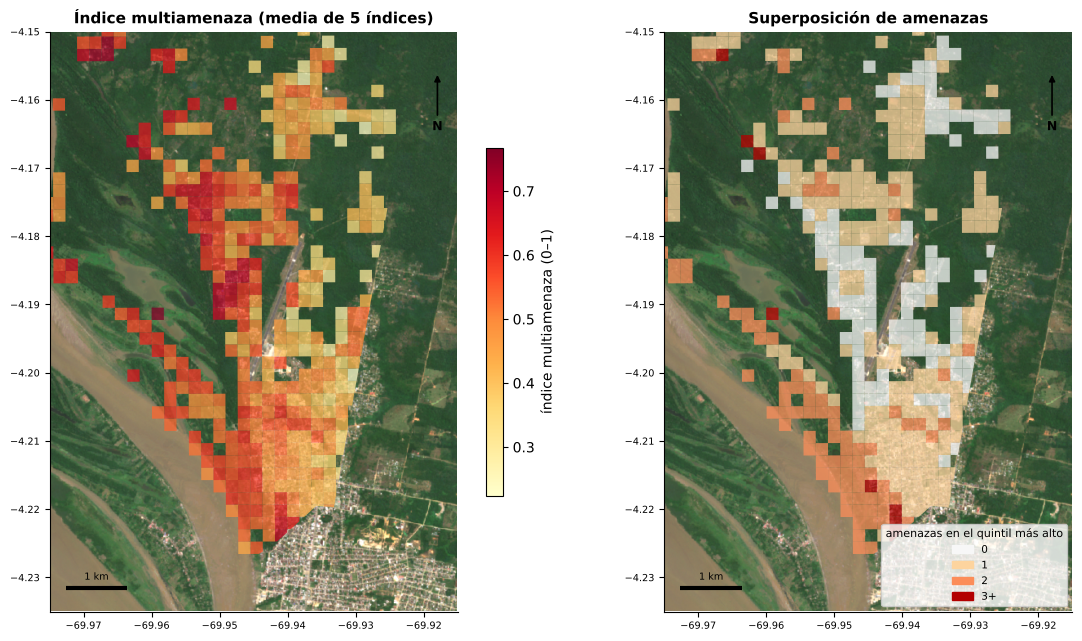

In [3]:
A = pd.DataFrame(index=con.index)
A["inundación fluvial"] = 0.5 * riesgo.normalizar(con["prof_rp100_m"].fillna(0)) + 0.5 * riesgo.normalizar(con["hand_m"], invertir=True)
A["erosión de orillas"] = riesgo.normalizar(con["dist_orilla_m"], invertir=True)
A["calor"] = riesgo.normalizar(con["lst_c"])
A["incendio (interfaz)"] = riesgo.normalizar(con["dist_foco_m"], invertir=True)
A["encharcamiento"] = riesgo.normalizar(con["prof_depresion_m"].fillna(0))
altos = (A >= 0.8)
con["n_amenazas_altas"] = altos.sum(axis=1)
con["indice_multiamenaza"] = A.mean(axis=1)
fig, ax = plt.subplots(1, 2, figsize=(12, 6.5))
viz.mapa_celdas(con, "indice_multiamenaza", ax=ax[0], cmap="YlOrRd", etiqueta="índice multiamenaza (0–1)", titulo="Índice multiamenaza (media de 5 índices)")
cats = ["0", "1", "2", "3+"]
con["n_cat"] = pd.cut(con["n_amenazas_altas"], [-1, 0, 1, 2, 10], labels=cats).astype(str)
viz.mapa_celdas(con, "n_cat", ax=ax[1], categorias=cats, colores=["#f7f7f7", "#fdd49e", "#fc8d59", "#b30000"],
                etiqueta="amenazas en el quintil más alto", titulo="Superposición de amenazas")
fig.tight_layout()
display(con.groupby("n_cat")[["n_edif", "poblacion"]].sum().round(0).rename(index=lambda x: f"{x} amenazas altas"))

**Lectura.** Las celdas con dos o más amenazas en su quintil más alto están sobre todo en la **franja ribereña y las
zonas bajas** del occidente y sur de la cabecera, donde coinciden inundación, erosión y encharcamiento. El calor
domina el centro denso, y el incendio la periferia norte sobre la vía a Tarapacá: son geografías distintas que
piden medidas distintas.

In [4]:
corr = A.corr(method="spearman").round(2)
display(Markdown("**Correlación entre índices de amenaza** (valores negativos indican que las amenazas ocurren en lugares distintos):"))
display(corr)

**Correlación entre índices de amenaza** (valores negativos indican que las amenazas ocurren en lugares distintos):

,inundación fluvial,erosión de orillas,calor,incendio (interfaz),encharcamiento
inundación fluvial,1.00,0.66,-0.18,0.14,-0.21
erosión de orillas,0.66,1.00,0.13,-0.20,-0.51
calor,-0.18,0.13,1.00,-0.66,-0.09
incendio (interfaz),0.14,-0.20,-0.66,1.00,0.21
encharcamiento,-0.21,-0.51,-0.09,0.21,1.00


## 2. Matriz de riesgos clave

In [5]:
from leticia import exposicion, fuentes, hidro
from leticia.config import parametros
ph = parametros()["hidrologia"]
edif = exposicion.edificaciones_urbanas()
pob = con["poblacion"].sum()
nivel = hidro.limpiar_nivel(fuentes.nivel_rio())
dias4 = hidro.dias_bajo_umbral(nivel, ph["umbral_estiaje_critico_cm"])
cckp = fuentes.cckp_tabla(["tasmax", "hi35", "spei12", "rx1day"], escenarios=["ssp245"], periodos=["2040-2059"], percentiles=["median"]).set_index("variable")["valor"]
expo = lambda col, umbral: (con.loc[A[col] >= umbral, "poblacion"].sum())
clave = pd.DataFrame([
    ["Inundación fluvial", "localizado", f"{expo('inundación fluvial', 0.8):,.0f} personas en el quintil más alto", "crecientes extremas más frecuentes desde 2000",
     "+0,5 a +1 m de creciente → +22 % a +56 % personas expuestas (3.1.d)", "alta"],
    ["Sequía y estiaje", "toda la ciudad", f"{pob:,.0f} personas dependen del río y de Yahuarcaca", f"2024: {int(dias4.get(2024, 0))} días bajo 4 m (récord)",
     f"SPEI-12 {cckp['spei12']:+.2f} a 2050 (SSP2-4.5)", "alta"],
    ["Erosión y dinámica fluvial", "localizado y sistémico", f"{expo('erosión de orillas', 0.8):,.0f} personas cerca de la orilla", "flujo desplazado al brazo peruano",
     "acceso al río comprometido sin intervención", "alta"],
    ["Calor extremo", "localizado", f"{expo('calor', 0.8):,.0f} personas en las celdas más calientes", "+0,2 °C/década en Tmax",
     f"Tmax {cckp['tasmax']:+.1f} °C y {cckp['hi35']:+.0f} días con índice de calor > 35 °C (SSP2-4.5, 2050)", "alta"],
    ["Incendios y humo", "periferia y toda la ciudad (humo)", f"{expo('incendio (interfaz)', 0.8):,.0f} personas cerca de focos", "pico de focos en 2024",
     "más días secos y cálidos", "media"],
    ["Lluvias intensas y vendavales", "localizado y toda la ciudad", f"{expo('encharcamiento', 0.8):,.0f} personas en depresiones", "vendavales casi anuales desde 2021",
     f"Rx1day {cckp['rx1day']:+.1f} mm (SSP2-4.5, 2050)", "media"],
], columns=["riesgo", "alcance", "exposición actual", "señal observada", "señal futura", "urgencia"]).set_index("riesgo")
clave["exposición actual"] = clave["exposición actual"].str.replace(",", ".")
clave["señal futura"] = clave["señal futura"].str.replace(",", ".", regex=False)
display(clave)

,alcance,exposición actual,señal observada,señal futura,urgencia
riesgo,,,,,
Inundación fluvial,localizado,1.965 personas en el quintil más alto,crecientes extremas más frecuentes desde 2000,+0.5 a +1 m de creciente → +22 % a +56 % perso...,alta
Sequía y estiaje,toda la ciudad,46.507 personas dependen del río y de Yahuarcaca,2024: 52 días bajo 4 m (récord),SPEI-12 -0.62 a 2050 (SSP2-4.5),alta
Erosión y dinámica fluvial,localizado y sistémico,5.312 personas cerca de la orilla,flujo desplazado al brazo peruano,acceso al río comprometido sin intervención,alta
Calor extremo,localizado,34.559 personas en las celdas más calientes,"+0,2 °C/década en Tmax",Tmax +1.2 °C y +85 días con índice de calor > ...,alta
Incendios y humo,periferia y toda la ciudad (humo),1.239 personas cerca de focos,pico de focos en 2024,más días secos y cálidos,media
Lluvias intensas y vendavales,localizado y toda la ciudad,7.049 personas en depresiones,vendavales casi anuales desde 2021,Rx1day +2.8 mm (SSP2-4.5. 2050),media


## 3. Cascadas: cómo se encadenan los riesgos

```{mermaid}
flowchart LR
  EN["El Niño + Atlántico cálido<br/>+ calentamiento global"] --> S["Sequía extrema<br/>(2023–2024)"]
  S --> V["Vaciante récord<br/>2,24 m en 2024"]
  S --> F["Incendios y humo"]
  S --> C["Olas de calor"]
  V --> N["Navegación interrumpida"]
  V --> A["Bocatoma de Yahuarcaca<br/>sin agua"]
  SED["Sedimentación del<br/>brazo colombiano"] --> N
  N --> P["Alza de precios,<br/>escasez de alimentos y combustible"]
  A --> H["Racionamiento,<br/>enfermedades hídricas"]
  A --> T["Agua almacenada<br/>en tanques"] --> DG["Criaderos de Aedes:<br/>dengue"]
  C --> DG
  F --> H2["Enfermedades respiratorias"]
  C --> H2
  LN["La Niña"] --> I["Crecientes extremas"]
  I --> E["Erosión de orillas<br/>y barrancos"]
  I --> D["Viviendas ribereñas<br/>inundadas"]
```

La sequía de 2023–2024 mostró que los riesgos de Leticia **no ocurren aislados**: una misma anomalía climática
desencadena aislamiento, desabastecimiento, fuego, humo y calor, y se suma a la sedimentación del cauce. La gestión
debe planear para esas combinaciones, no amenaza por amenaza [@marengo2024spa].

## 4. Prioridades de gestión

```{list-table} Medidas priorizadas por proceso de la Ley 1523 de 2012
:header-rows: 1
* - Proceso
  - Medida
  - Riesgos que atiende
* - Conocimiento
  - Modelo hidráulico local del Amazonas frente a Leticia (batimetría, topografía LiDAR de la franja ribereña) y estudios básicos de amenaza para el PBOT (Decreto 1077 de 2015)
  - Inundación, erosión, estiaje
* - Conocimiento
  - Umbrales de alerta en la regla de Leticia acordados con IDEAM, Capitanía de Puerto y Alcaldía; monitoreo anual del cauce con Landsat/Sentinel-2
  - Inundación, estiaje, dinámica fluvial
* - Reducción
  - Fuentes alternas de agua (pozos, captación de lluvia, almacenamiento) y protección de la cuenca de Yahuarcaca
  - Sequía, desabastecimiento
* - Reducción
  - Arborización urbana, techos frescos y conservación del bosque periurbano
  - Calor, incendio, encharcamiento
* - Reducción
  - Control de construcciones nuevas en la franja de orilla activa y en zonas bajas; drenaje pluvial con factor de seguridad climático
  - Erosión, inundación, encharcamiento
* - Manejo
  - Reservas estratégicas de alimentos y combustible antes de la vaciante; protocolo de alerta temprana con pronósticos de GloFAS e IDEAM
  - Estiaje, aislamiento
* - Manejo
  - Prohibición y control de quemas en temporada seca; alertas de calidad del aire y de calor para la población sensible
  - Incendios, humo, calor
* - Gobernanza
  - Actualizar el PMGRD de Leticia (2013) con escenarios de cambio climático e integrarlo con el PIGCCT de Amazonas y la cooperación binacional con Perú y Brasil (OTCA)
  - Todos
```

:::{important} Alcance
Los resultados de este libro son **indicativos**: combinan datos abiertos globales y nacionales a resoluciones de
10 a 90 m, con supuestos documentados en `parametros.yaml`. No reemplazan los estudios básicos y detallados de
amenaza que exige la norma colombiana, pero muestran **dónde y por qué** conviene hacerlos primero.
:::